In [1]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv("/marketing_AB.csv")


In [3]:
print(df.head())


   Unnamed: 0  user id test group  converted  total ads most ads day  \
0           0  1069124         ad      False        130       Monday   
1           1  1119715         ad      False         93      Tuesday   
2           2  1144181         ad      False         21      Tuesday   
3           3  1435133         ad      False        355      Tuesday   
4           4  1015700         ad      False        276       Friday   

   most ads hour  
0             20  
1             22  
2             18  
3             10  
4             14  


In [4]:
print(df.shape)


(588101, 7)


In [5]:
print(df.groupby("test group")["converted"].mean())

test group
ad     0.025547
psa    0.017854
Name: converted, dtype: float64


In [6]:
df = df.drop(columns=["Unnamed: 0"])          # just an old index, adds no information


In [7]:
df.columns = df.columns.str.replace(" ", "_") # test group -> test_group, easier to type


In [8]:
print(df.isnull().sum())                      # any missing values?
print("duplicate users:", df["user_id"].duplicated().sum())  # each user should appear once
print(df["test_group"].value_counts())        # group sizes
print(df.dtypes)

user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64
duplicate users: 0
test_group
ad     564577
psa     23524
Name: count, dtype: int64
user_id           int64
test_group       object
converted          bool
total_ads         int64
most_ads_day     object
most_ads_hour     int64
dtype: object


In [9]:
g = df.groupby("test_group")["converted"].agg(["sum", "count", "mean"])
print(g)
p_ad, p_psa = g.loc["ad","mean"], g.loc["psa","mean"]
print("absolute lift (pp):", round((p_ad - p_psa)*100, 3))
print("relative lift (%):", round((p_ad - p_psa)/p_psa*100, 2))

              sum   count      mean
test_group                         
ad          14423  564577  0.025547
psa           420   23524  0.017854
absolute lift (pp): 0.769
relative lift (%): 43.09


In [10]:
from scipy.stats import chi2_contingency
table = pd.crosstab(df["test_group"], df["converted"])
print(table)
chi2, p, dof, expected = chi2_contingency(table, correction=False)
print("chi2:", chi2, "p-value:", p, "df:", dof)

converted    False  True 
test_group               
ad          550154  14423
psa          23104    420
chi2: 54.318051591383124 p-value: 1.7052807161560133e-13 df: 1


In [11]:
from statsmodels.stats.proportion import confint_proportions_2indep
low, high = confint_proportions_2indep(
    g.loc["ad","sum"], g.loc["ad","count"],
    g.loc["psa","sum"], g.loc["psa","count"], compare="diff")
print("95% CI for difference (pp):", round(low*100,3), "to", round(high*100,3))

95% CI for difference (pp): 0.587 to 0.936


In [12]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

n_ad, n_psa = g.loc["ad","count"], g.loc["psa","count"]
ratio = n_ad / n_psa
analysis = NormalIndPower()

# 1) Smallest effect we could reliably detect (MDE) with 80% power
h = analysis.solve_power(effect_size=None, nobs1=n_psa, alpha=0.05, power=0.8, ratio=ratio)
p_mde = np.sin(np.arcsin(np.sqrt(p_psa)) + h/2)**2
print("MDE (absolute, pp):", round((p_mde - p_psa)*100, 3))
print("MDE (relative %):", round((p_mde - p_psa)/p_psa*100, 2))

# 2) Power of the lift we actually observed
h_obs = proportion_effectsize(p_ad, p_psa)
print("power at observed effect:", analysis.solve_power(effect_size=h_obs, nobs1=n_psa, alpha=0.05, ratio=ratio))

MDE (absolute, pp): 0.255
MDE (relative %): 14.3
power at observed effect: 0.9999999990438161


test_group
ad     24.823365
psa    24.761138
Name: total_ads, dtype: float64
most_ads_day  Friday  Monday  Saturday  Sunday  Thursday  Tuesday  Wednesday
test_group                                                                  
ad             0.157   0.148     0.140   0.146     0.140    0.132      0.137
psa            0.162   0.149     0.121   0.130     0.166    0.124      0.148


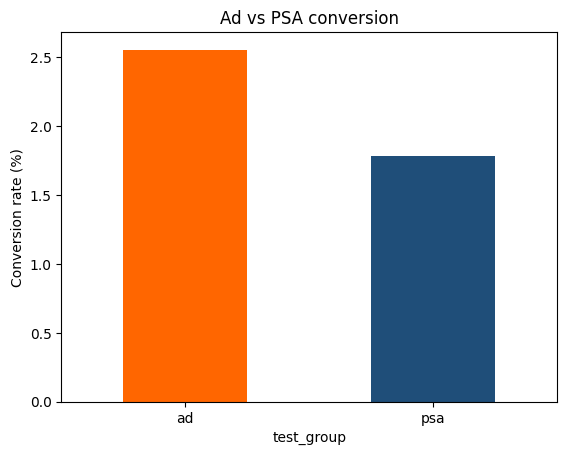

In [13]:
import matplotlib.pyplot as plt
print(df.groupby("test_group")["total_ads"].mean())
print(df.groupby("test_group")["most_ads_day"].value_counts(normalize=True).unstack().round(3))

g["mean"].mul(100).plot(kind="bar", color=["#ff6600","#1f4e79"])
plt.ylabel("Conversion rate (%)"); plt.title("Ad vs PSA conversion"); plt.xticks(rotation=0)
plt.savefig("conversion_rates.png", dpi=150, bbox_inches="tight"); plt.show()